In [3]:
import os
import typing

# Import your dependencies
import joblib
import pandas as pd
import numpy as np
import scipy
import sklearn.metrics

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

from sklearn.base import clone as sk_clone
from sklearn.pipeline import Pipeline

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [4]:
X_train = pd.read_parquet("data/X_train.parquet")
y_train = pd.read_parquet("data/y_train.parquet")
X_test = pd.read_parquet("data/X_test.reduced.parquet")

In [55]:
df = X_train
df.head()

#np.min(df["value"].values)

np.float64(-2.2848206626491874)

In [6]:
#X_train.describe()
display(df.groupby("period")["value"].describe())
#print(df["period"] == 1).mean()

value_col = "value"
time_col = "time"
period_col = "period"
id_col = "id"
target_col = "target"

,count,mean,std,min,25%,50%,75%,max
period,,,,,,,,
0,17469105.0,0.000571,0.108955,-2.284821,-0.004582,0.000080,0.005015,412.5
1,6246629.0,0.000578,0.035626,-0.966667,-0.004362,0.000108,0.004926,48.5


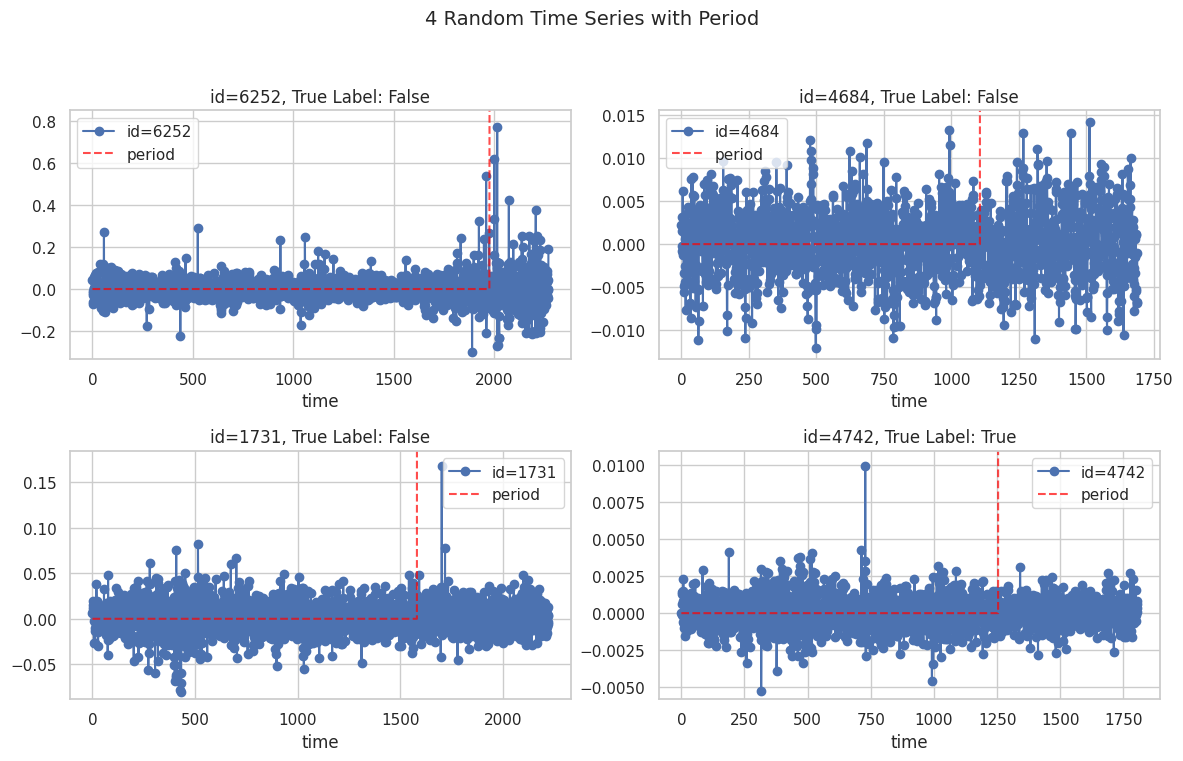

In [53]:
"""
Display n random time series from a DataFrame with MultiIndex (id, time).
"""
n=4
random_state=42

rng = np.random.RandomState(random_state)
ids = df.index.get_level_values("id").unique()
chosen_ids = rng.choice(ids, size=min(n, len(ids)), replace=False)

sns.set(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, idx in zip(axes, chosen_ids):
    ts = df.xs(idx, level="id")[value_col]
    period = df.xs(idx, level="id")[period_col]
    
    ax.plot(ts.index, ts.values, marker="o", linestyle="-", label=f"id={idx}")
    ax.plot(period.index, period.values, color="red", linestyle="--", alpha=0.7, label="period")
    true_label = str(y_train.xs(idx).values[0])
    ax.set_title(f"id={idx}, True Label: {true_label}")
    ax.set_xlabel("time")
    ax.set_ylim(ts.min() - 0.1 * abs(ts.min()), ts.max() + 0.1 * abs(ts.max()))  # Add padding to min/max
    ax.grid(True)
    ax.legend()

# Hide unused axes
for j in range(len(chosen_ids), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f"{len(chosen_ids)} Random Time Series with Period", fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


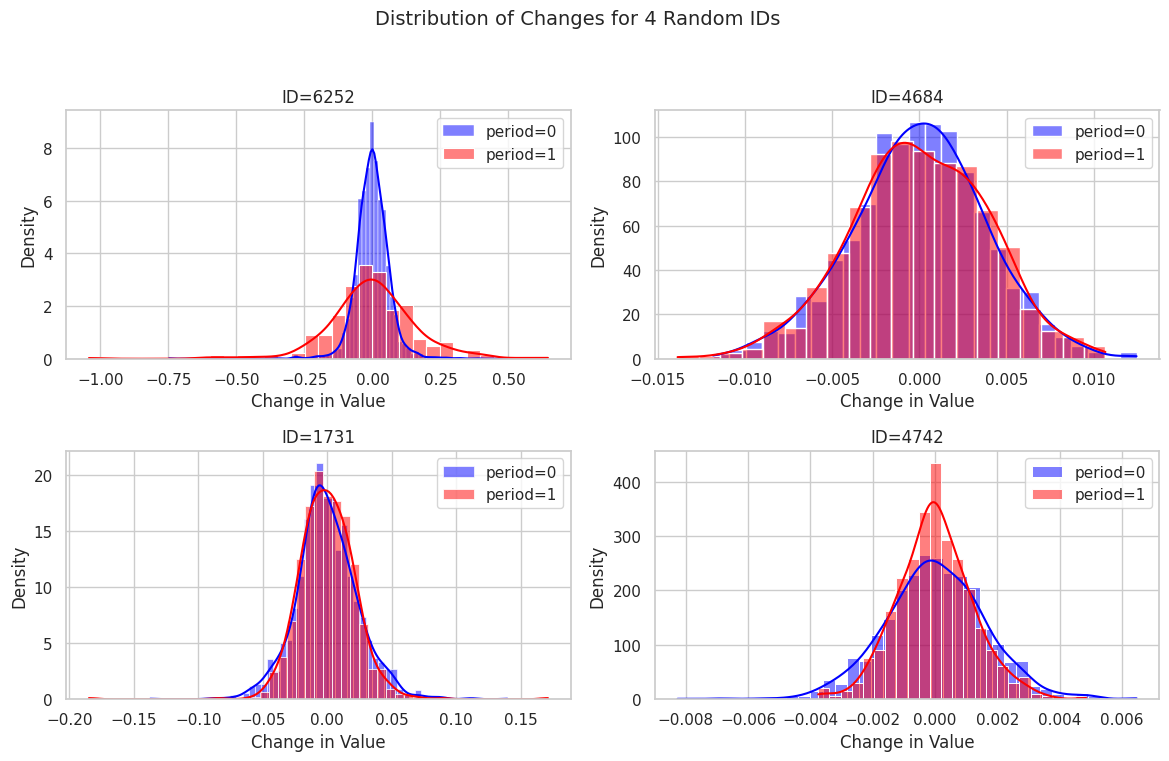

In [15]:
"""
Display the distribution of changes in `value` for `period=0` and `period=1`
for n random IDs. Each plot corresponds to one ID, with different colors for
period=0 and period=1.
"""
rng = np.random.RandomState(random_state)
ids = df.index.get_level_values("id").unique()
chosen_ids = rng.choice(ids, size=min(n, len(ids)), replace=False)

sns.set(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, idx in zip(axes, chosen_ids):
    # Extract data for the current ID and create a copy to avoid SettingWithCopyWarning
    sub_df = df.xs(idx, level="id").copy()
    sub_df["change"] = sub_df[value_col].diff()  # Calculate changes (diff)

    # Separate changes by period
    changes_0 = sub_df[sub_df[period_col] == 0]["change"].dropna()
    changes_1 = sub_df[sub_df[period_col] == 1]["change"].dropna()

    # Plot distributions
    sns.histplot(changes_0, color="blue", label="period=0", kde=True, stat="density", alpha=0.5, ax=ax)
    sns.histplot(changes_1, color="red", label="period=1", kde=True, stat="density", alpha=0.5, ax=ax)

    ax.set_title(f"ID={idx}")
    ax.set_xlabel("Change in Value")
    ax.legend()
    ax.grid(True)

# Hide unused axes
for j in range(len(chosen_ids), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f"Distribution of Changes for {len(chosen_ids)} Random IDs", fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


In [23]:
from statsmodels.tsa.ar_model import AutoReg
import numpy as np

def find_best_lag(series, max_lag=12):
    """
    Find the best lag for an AutoRegressive (AR) model by minimizing AIC.
    Args:
        series (pd.Series): The time series data.
        max_lag (int): The maximum lag to consider.
    Returns:
        int: The best lag.
    """
    # Ensure the index is a simple integer index
    series = series.reset_index(drop=True)

    best_lag = None
    best_aic = np.inf

    for lag in range(1, max_lag + 1):
        try:
            model = AutoReg(series, lags=lag, old_names=False).fit()
            if model.aic < best_aic:
                best_aic = model.aic
                best_lag = lag
        except Exception as e:
            print(f"Failed to fit model for lag={lag}: {e}")

    return best_lag

# Example usage
# Assuming `series` is your time series data (e.g., df['value'])
# best_lag = find_best_lag(series, max_lag=12)

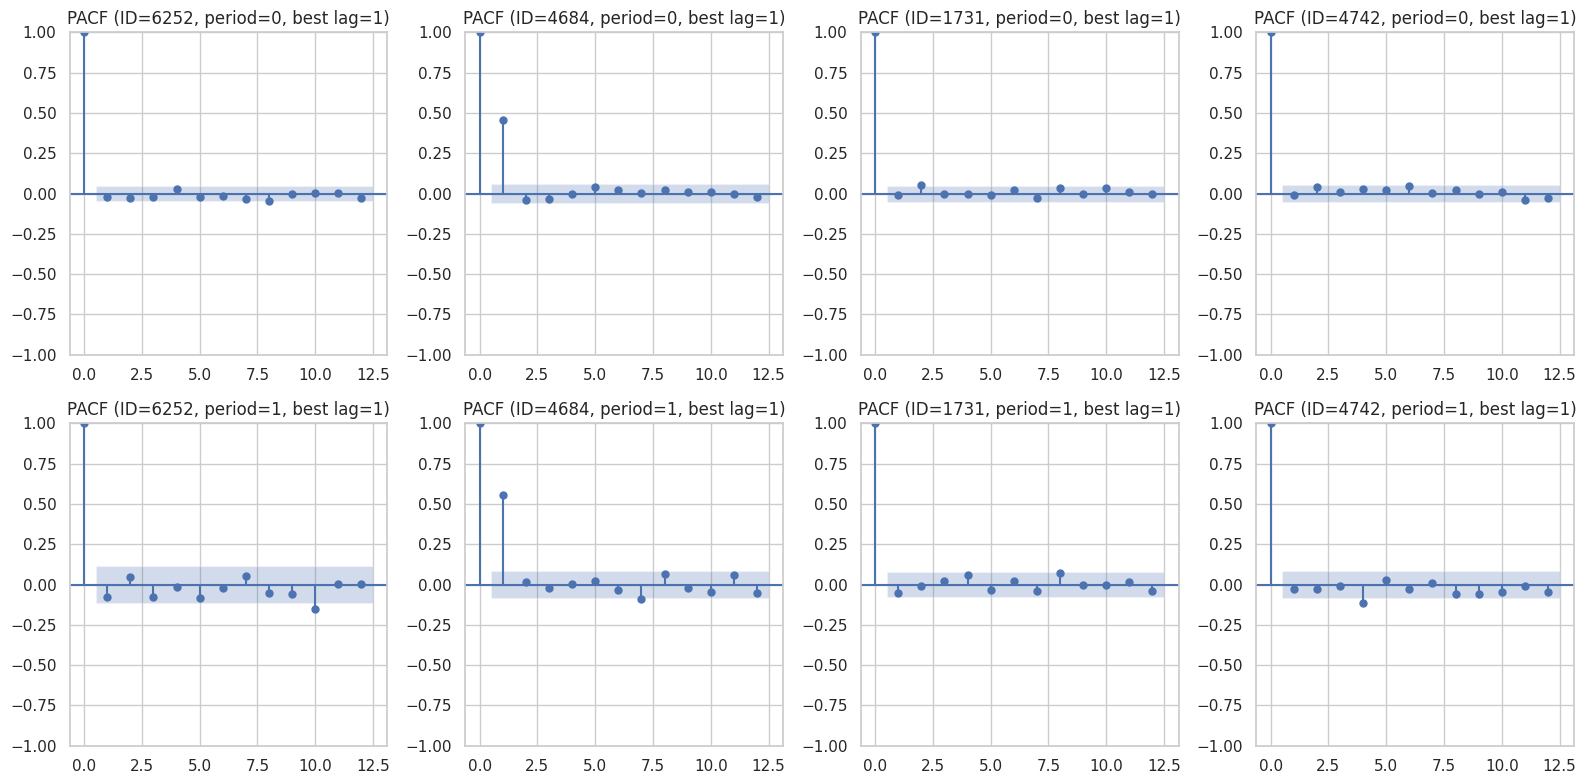

In [24]:
"""
Display the Partial Autocorrelation Function (PACF) for `value` for `period=0` and `period=1`
for n random IDs. Each plot corresponds to one ID, with the best lag displayed in the title.
"""
max_lag=12
rng = np.random.RandomState(random_state)
ids = df.index.get_level_values("id").unique()
chosen_ids = rng.choice(ids, size=min(n, len(ids)), replace=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))  # 2 rows (period=0 and period=1), 4 columns (one per ID)
axes = axes.ravel()

for i, idx in enumerate(chosen_ids):
    # Extract data for the current ID
    sub_df = df.xs(idx, level="id")
    
    # Separate data by period
    values_0 = sub_df[sub_df[period_col] == 0][value_col].dropna()
    values_1 = sub_df[sub_df[period_col] == 1][value_col].dropna()

    # Find best lag for period=0
    best_lag_0 = find_best_lag(values_0, max_lag=max_lag)
    # Plot PACF for period=0
    ax_0 = axes[i]
    plot_pacf(values_0, ax=ax_0, lags=max_lag, title=f"PACF (ID={idx}, period=0, best lag={best_lag_0})")
    ax_0.grid(True)

    # Find best lag for period=1
    best_lag_1 = find_best_lag(values_1, max_lag=max_lag)
    # Plot PACF for period=1
    ax_1 = axes[i + len(chosen_ids)]
    plot_pacf(values_1, ax=ax_1, lags=max_lag, title=f"PACF (ID={idx}, period=1, best lag={best_lag_1})")
    ax_1.grid(True)

plt.tight_layout()
plt.show()

In [26]:
from statsmodels.tsa.seasonal import seasonal_decompose

def check_seasonality(series, model="additive", period=None):
    """
    Decompose the time series and check for seasonality.
    Args:
        series (pd.Series): The time series data.
        model (str): "additive" or "multiplicative".
        period (int): The seasonal period (e.g., 12 for monthly data).
    Returns:
        bool: True if seasonality is detected, False otherwise.
    """
    decomposition = seasonal_decompose(series, model=model, period=period)
    seasonal_strength = decomposition.seasonal.std() / series.std()
    return seasonal_strength > 0.1  # Threshold for seasonality strength

# Example usage
# Assume `df` has a MultiIndex with 'id' and 'time', and 'value' is the column of interest
seasonal_ids = []
for idx in df.index.get_level_values("id").unique():
    ts = df.xs(idx, level="id")["value"]
    if check_seasonality(ts, period=12):  # Adjust `period` based on your data
        seasonal_ids.append(idx)

print("IDs with seasonality:", seasonal_ids)

IDs with seasonality: [61, 83, 182, 198, 211, 221, 223, 270, 291, 298, 319, 322, 347, 361, 389, 399, 438, 470, 516, 523, 526, 577, 578, 595, 604, 644, 654, 679, 724, 770, 774, 964, 993, 1019, 1055, 1111, 1149, 1172, 1187, 1192, 1245, 1308, 1358, 1369, 1379, 1400, 1440, 1491, 1502, 1519, 1551, 1558, 1565, 1637, 1645, 1650, 1680, 1688, 1783, 1845, 1853, 1857, 1881, 1907, 1948, 1962, 1968, 2021, 2024, 2035, 2045, 2069, 2121, 2127, 2132, 2137, 2144, 2168, 2178, 2192, 2240, 2245, 2250, 2322, 2338, 2344, 2352, 2393, 2429, 2445, 2453, 2518, 2521, 2539, 2542, 2545, 2585, 2607, 2638, 2639, 2647, 2655, 2664, 2695, 2712, 2722, 2895, 2898, 2940, 2951, 2983, 3011, 3034, 3050, 3123, 3138, 3145, 3181, 3196, 3239, 3288, 3302, 3313, 3316, 3324, 3343, 3367, 3407, 3427, 3445, 3459, 3494, 3503, 3508, 3509, 3515, 3534, 3537, 3541, 3543, 3562, 3590, 3672, 3674, 3720, 3760, 3798, 3800, 3840, 3851, 3865, 3901, 3965, 3987, 4030, 4055, 4056, 4070, 4131, 4177, 4196, 4204, 4215, 4227, 4237, 4249, 4260, 4280, 4287

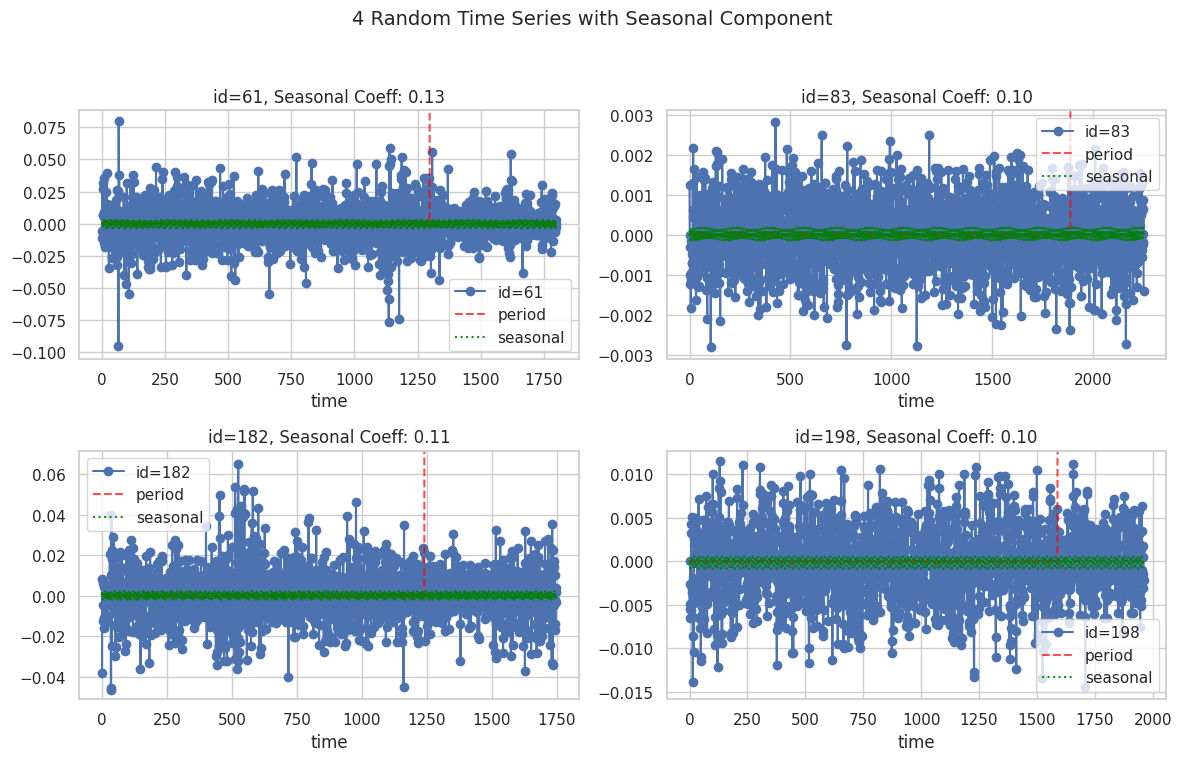

In [33]:
from statsmodels.tsa.seasonal import seasonal_decompose

sns.set(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, idx in zip(axes, chosen_ids):
    ts = df.xs(idx, level="id")[value_col]
    period = df.xs(idx, level="id")[period_col]
    
    # Decompose the time series to extract the seasonal component
    decomposition = seasonal_decompose(ts, model="additive", period=12)  # Adjust `period` as needed
    seasonal = decomposition.seasonal
    
    # Calculate the seasonal strength coefficient
    seasonal_strength = seasonal.std() / ts.std()
    
    # Plot the original time series
    ax.plot(ts.index, ts.values, marker="o", linestyle="-", label=f"id={idx}")
    
    # Plot the period line
    ax.plot(period.index, period.values, color="red", linestyle="--", alpha=0.7, label="period")
    
    # Plot the seasonal component
    ax.plot(seasonal.index, seasonal.values, color="green", linestyle=":", alpha=0.9, label="seasonal")
    
    # Add the seasonal strength coefficient to the title
    ax.set_title(f"id={idx}, Seasonal Coeff: {seasonal_strength:.2f}")
    ax.set_xlabel("time")
    ax.set_ylim(ts.min() - 0.1 * abs(ts.min()), ts.max() + 0.1 * abs(ts.max()))  # Add padding to min/max
    ax.grid(True)
    ax.legend()

# Hide unused axes
for j in range(len(chosen_ids), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f"{len(chosen_ids)} Random Time Series with Seasonal Component", fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [34]:
pred = pd.read_parquet("data/prediction.parquet")

In [52]:
pred.head()
pred.shape
X_test.head()
str(y_train.xs(0).values[0]) #.head()

'False'